# Практична робота 4. План обчислювального експерименту, бенчмарк та абляційне дослідження
**Тема:** гібридне оцінювання відповідності резюме вакансії на основі семантичних векторів і правил.
**Виконав:** Кузьмук В. І., КНм-26. **Бенчмарк:** Vanetik & Kogan (2023), *Information* 14(8):468 — 5 вакансій, 65 резюме, ранжування двох анотаторів для CV 1–30.

In [1]:
import sys, json, time, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr
from cvmatch.experiment import *
from cvmatch.method import vacancy_model, cv_years
SEED = 42; np.random.seed(SEED)            # фіксація завадового фактора
sns.set_theme(style='whitegrid')
print(json.dumps(env_info(), indent=1, ensure_ascii=False))

{
 "python": "3.13.16",
 "os": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39",
 "cpu": "x86_64",
 "n_cpu": 2,
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scikit-learn": "1.9.1",
 "scipy": "1.18.1",
 "spacy": "3.8.16",
 "spacy_model": "en_core_web_md-3.8.0"
}


## Етап 1. Специфікація експерименту
| Тип змінної | Змінна | Рівні / одиниці |
|---|---|---|
| Незалежна X1 | Векторне подання тексту | TF-IDF (лексичне), LSA-50 (латентно-семантичне), spaCy en_core_web_md (word vectors, 300-d) |
| Незалежна X2 | Сила шару правил α (Модуль 2) | 0 (вимкнено), 0.5, 1.0 |
| Залежна Y1 | Якість ранжування вакансій для кожного CV | Spearman ρ, NDCG@5, Top-1 |
| Залежна Y2 | Часові витрати | затримка, мс на пару; час підготовки (векторизації), с |
| Завадові | seed (LSA), розбіжність анотаторів, якість парсингу DOCX, фонові процеси | seed=42; консенсус двох анотаторів; однакове середовище |

## Етап 2. Підготовка та валідація датасету

In [2]:
v, cvs, ann, cons, corpus = setup('../data/raw')
print('Вакансій:', len(v), ' резюме:', len(cvs), ' розмічених CV:', len(LABELED))
print(v[['vac_idx','job_title']].to_string(index=False))
bad = ann[~ann.valid].groupby(['annotator','cv_id']).size().index.tolist()
print('Невалідні масиви ранжувань (дублікати позицій):', bad, '-> для цих CV використовується лише другий анотатор')
vm = pd.DataFrame([dict(vac=j, n_critical=len(m['critical']), n_core=len(m['core']), n_optional=len(m['optional']),
       min_years=m['min_years']) for j, m in ((j, vacancy_model(t)) for j, t in zip(v.vac_idx, v.job_description))])
vm

Вакансій: 5  резюме: 65  розмічених CV: 30
 vac_idx                                              job_title
       1                              Software Developer - .Net
       2                              Remote Software Developer
       3 Junior Level Software Developer (1-4 years experience)
       4                             Backend Software Developer
       5                                     Software Developer
Невалідні масиви ранжувань (дублікати позицій): [(1, 9), (1, 28)] -> для цих CV використовується лише другий анотатор


,vac,n_critical,n_core,n_optional,min_years
0,1,3,0,12,5
1,2,9,2,0,3
2,3,4,0,0,0
3,4,7,2,12,3
4,5,3,0,2,2


In [3]:
# Узгодженість анотаторів (межа досяжної якості): Spearman між ранжуваннями для кожного CV
a = ann[ann.valid].pivot_table(index=['cv_id','vac_idx'], columns='annotator', values='position').dropna()
iaa = pd.Series({i: spearmanr(g[1], g[2]).correlation for i, g in a.groupby(level=0)})
print(f'Inter-annotator agreement: ρ = {iaa.mean():.3f} ± {iaa.std():.3f} (n = {len(iaa)} CV)')
print('Середня консенсусна позиція вакансії (1 = найкраща):', cons.groupby('vac_idx').pos.mean().round(2).to_dict())

Inter-annotator agreement: ρ = 0.171 ± 0.491 (n = 28 CV)
Середня консенсусна позиція вакансії (1 = найкраща): {1: 2.4, 2: 2.45, 3: 2.78, 4: 3.03, 5: 4.33}


In [4]:
# Стратифіковане розбиття 30 розмічених CV на калібрувальну (80%) та валідаційну (20%) підвибірки
best = cons.loc[cons.groupby('cv_id').pos.idxmin()].set_index('cv_id').vac_idx
strata = best.reindex(LABELED).map(lambda j: j if j in (1, 2) else 0)   # 3 страти: вак.1, вак.2, інші
cal_ids, val_ids = train_test_split(LABELED, test_size=0.2, stratify=strata, random_state=SEED)
cal_ids, val_ids = sorted(cal_ids), sorted(val_ids)
print('Калібрування:', len(cal_ids), cal_ids); print('Валідація:', len(val_ids), val_ids)
# Контроль витоку даних: словник TF-IDF/LSA навчається лише на НЕРОЗМІЧЕНИХ CV (31–65) і вакансіях
labeled_texts = set(cvs[cvs.cv_id.isin(LABELED)].text)
assert not labeled_texts & set(corpus), 'витік: розмічені CV у корпусі векторизатора'
print('Корпус векторизатора:', len(corpus), 'документів; перетин із розміченими CV: 0 -> витоку немає')

Калібрування: 24 [1, 2, 4, 5, 6, 7, 8, 9, 11, 12, 13, 15, 17, 18, 19, 20, 22, 23, 24, 26, 27, 28, 29, 30]
Валідація: 6 [3, 10, 14, 16, 21, 25]
Корпус векторизатора: 40 документів; перетин із розміченими CV: 0 -> витоку немає


## Етап 3. Базова модель (Baseline M0) — лексичний пошук TF-IDF

In [5]:
base_cfg = dict(kind='tfidf', use_aspects=False, use_rules=False)
d0, m0, _ = evaluate(base_cfg, v, cvs, cons, corpus, val_ids)
d0_all, _, _ = evaluate(base_cfg, v, cvs, cons, corpus)
print('Validation:', d0[['spearman','ndcg5','top1']].mean().round(4).to_dict())
print('Усі 30 CV:  ', d0_all[['spearman','ndcg5','top1','latency_ms','t_prep_s']].mean().round(4).to_dict())

Validation: {'spearman': 0.2517, 'ndcg5': 0.9058, 'top1': 0.6667}
Усі 30 CV:   {'spearman': 0.0615, 'ndcg5': 0.8812, 'top1': 0.4, 'latency_ms': 0.0173, 't_prep_s': 0.1455}


## Етап 4. Абляційне дослідження
Модуль 1 — аспектна декомпозиція (загальний текст / навички / досвід, ваги 0.5/0.3/0.2, як у CVMaster).
Модуль 2 — детермінований шар правил (покриття навичок, досвід, штраф за критичні прогалини та розмиті вимоги).

In [6]:
configs = {
  'Baseline (M0)': (base_cfg, 'TF-IDF, загальний текст'),
  'Full (M1)':     (dict(kind='spacy', use_aspects=True,  use_rules=True),  'spaCy + Модуль 1 + Модуль 2'),
  'No-Mod1 (M2)':  (dict(kind='spacy', use_aspects=False, use_rules=True),  'Full без аспектної декомпозиції'),
  'No-Mod2 (M3)':  (dict(kind='spacy', use_aspects=True,  use_rules=False), 'Full без шару правил'),
}
rows = []
for name, (cfg, desc) in configs.items():
    dv, _, _ = evaluate(cfg, v, cvs, cons, corpus, val_ids)
    da, m, _ = evaluate(cfg, v, cvs, cons, corpus)
    rows.append({'Конфігурація': name, 'Фактори': desc, 'T_prep, с': da.t_prep_s.iloc[0], 'Затримка, мс/пару': m.latency_ms,
                 'ρ (Val)': dv.spearman.mean(), 'ρ (30 CV)': da.spearman.mean(), 'NDCG@5 (30 CV)': da.ndcg5.mean(), 'Top-1 (30 CV)': da.top1.mean()})
abl = pd.DataFrame(rows)
ref = abl.loc[abl['Конфігурація']=='Full (M1)', 'ρ (30 CV)'].item()
abl['Δρ відносно Full'] = abl['ρ (30 CV)'] - ref
abl.to_csv('../results/pr4_ablation.csv', index=False); abl.round(4)

,Конфігурація,Фактори,"T_prep, с","Затримка, мс/пару",ρ (Val),ρ (30 CV),NDCG@5 (30 CV),Top-1 (30 CV),Δρ відносно Full
0,Baseline (M0),"TF-IDF, загальний текст",0.0853,0.0130,0.2517,0.0615,0.8812,0.4000,0.2542
1,Full (M1),spaCy + Модуль 1 + Модуль 2,3.4472,0.0472,-0.0759,-0.1927,0.8251,0.2000,0.0000
2,No-Mod1 (M2),Full без аспектної декомпозиції,2.8235,0.0357,-0.2004,-0.2113,0.8244,0.2000,-0.0186
3,No-Mod2 (M3),Full без шару правил,3.0360,0.0174,0.2890,0.2024,0.8892,0.2333,0.3951


## Етап 4б. Калібрування α та ваг аспектів на калібрувальній підвибірці (24 CV) → перевірка на валідаційній (6 CV)

In [7]:
grid = []
for alpha in [0, 0.25, 0.5, 0.75, 1.0]:
    for w in [(1,0,0), (0.5,0.3,0.2), (0.34,0.33,0.33), (0.3,0.5,0.2), (0.3,0.2,0.5)]:
        dc, _, _ = evaluate(dict(kind='spacy', use_aspects=True, use_rules=alpha>0, weights=w, alpha=alpha), v, cvs, cons, corpus, cal_ids)
        grid.append(dict(alpha=alpha, weights=str(w), rho_cal=dc.spearman.mean()))
grid = pd.DataFrame(grid).sort_values('rho_cal', ascending=False); grid.to_csv('../results/pr4_calibration_grid.csv', index=False)
best_cfg = grid.iloc[0]; print('Найкраща конфігурація на калібруванні:', best_cfg.to_dict())
w_best = tuple(float(x) for x in best_cfg.weights.strip('()').split(','))
dv_best, _, _ = evaluate(dict(kind='spacy', use_aspects=True, use_rules=best_cfg.alpha>0, weights=w_best, alpha=best_cfg.alpha), v, cvs, cons, corpus, val_ids)
dv_def, _, _ = evaluate(dict(kind='spacy'), v, cvs, cons, corpus, val_ids)
print(f'Validation ρ: калібрований = {dv_best.spearman.mean():.3f}; евристичні параметри CVMaster (α=1, 0.5/0.3/0.2) = {dv_def.spearman.mean():.3f}')
grid.head(8).round(4)

Найкраща конфігурація на калібруванні: {'alpha': 0.0, 'weights': '(0.34, 0.33, 0.33)', 'rho_cal': 0.2018295837746765}


Validation ρ: калібрований = 0.204; евристичні параметри CVMaster (α=1, 0.5/0.3/0.2) = -0.076


,alpha,weights,rho_cal
2,0.00,"(0.34, 0.33, 0.33)",0.2018
1,0.00,"(0.5, 0.3, 0.2)",0.1808
4,0.00,"(0.3, 0.2, 0.5)",0.1582
3,0.00,"(0.3, 0.5, 0.2)",0.1492
0,0.00,"(1, 0, 0)",0.0212
18,0.75,"(0.3, 0.5, 0.2)",-0.2012
23,1.00,"(0.3, 0.5, 0.2)",-0.2012
12,0.50,"(0.34, 0.33, 0.33)",-0.2012


## Етап 5 / Самостійна робота. Повний факторний план 3 × 3 (подання × сила правил α)

In [8]:
fact = []
for kind in ['tfidf', 'lsa', 'spacy']:
    for alpha in [0, 0.5, 1.0]:
        d, m, _ = evaluate(dict(kind=kind, use_aspects=True, use_rules=alpha>0, alpha=alpha), v, cvs, cons, corpus)
        fact.append(dict(representation=kind, alpha=alpha, rho=d.spearman.mean(), rho_sd=d.spearman.std(),
                         ndcg5=d.ndcg5.mean(), top1=d.top1.mean(), t_prep_s=d.t_prep_s.iloc[0], latency_ms=m.latency_ms))
fact = pd.DataFrame(fact); fact.to_csv('../results/pr4_factorial.csv', index=False); fact.round(4)

,representation,alpha,rho,rho_sd,ndcg5,top1,t_prep_s,latency_ms
0,tfidf,0.0,0.0886,0.4099,0.8811,0.2667,0.1129,0.0576
1,tfidf,0.5,-0.1157,0.3997,0.8964,0.3667,0.0827,0.0747
2,tfidf,1.0,-0.0548,0.3119,0.9131,0.4333,0.0741,0.0685
3,lsa,0.0,0.1719,0.4060,0.8867,0.2333,0.1791,0.0171
4,lsa,0.5,-0.1311,0.5187,0.8346,0.2000,0.0714,0.0442
5,lsa,1.0,-0.1593,0.5112,0.8249,0.2000,0.0732,0.0454
6,spacy,0.0,0.2024,0.4787,0.8892,0.2333,3.6661,0.0167
7,spacy,0.5,-0.1847,0.4768,0.8268,0.2000,3.1109,0.0514
8,spacy,1.0,-0.1927,0.4637,0.8251,0.2000,3.3772,0.0491


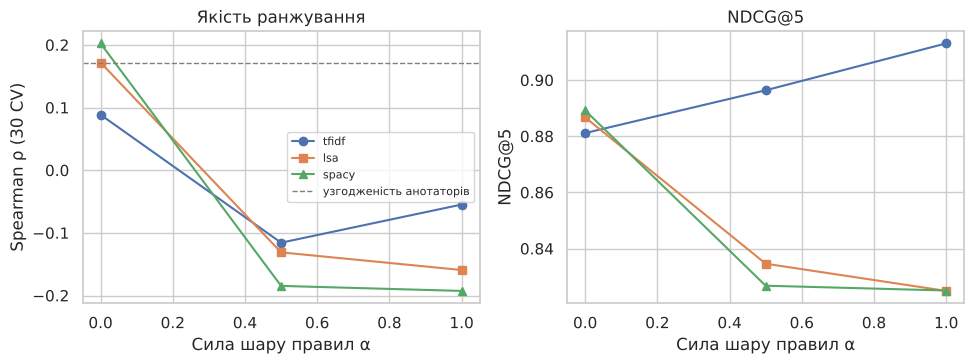

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for kind, mk in zip(['tfidf','lsa','spacy'], ['o','s','^']):
    d = fact[fact.representation==kind]
    ax[0].plot(d.alpha, d.rho, marker=mk, label=kind); ax[1].plot(d.alpha, d.ndcg5, marker=mk, label=kind)
ax[0].axhline(iaa.mean(), ls='--', c='grey', lw=1, label='узгодженість анотаторів')
ax[0].set(xlabel='Сила шару правил α', ylabel='Spearman ρ (30 CV)', title='Якість ранжування')
ax[1].set(xlabel='Сила шару правил α', ylabel='NDCG@5', title='NDCG@5')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('../figures/pr4_factorial.png', dpi=200); plt.show()

In [10]:
# Шаблонний модуль автоматичної фіксації часових та обчислювальних витрат
import contextlib, resource
@contextlib.contextmanager
def track(name, log):
    t0, c0 = time.perf_counter(), time.process_time()
    yield
    log.append(dict(stage=name, wall_s=round(time.perf_counter()-t0, 4), cpu_s=round(time.process_time()-c0, 4),
                    max_rss_mb=round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024, 1)))
log = []
with track('load data', log): _ = setup('../data/raw')
with track('evaluate Full (30 CV x 5 vacancies)', log): evaluate(dict(kind='spacy'), v, cvs, cons, corpus)
pd.DataFrame(log)

,stage,wall_s,cpu_s,max_rss_mb
0,load data,0.7857,0.7660,1188.8
1,evaluate Full (30 CV x 5 vacancies),4.1580,4.1227,1210.4
